# Numerical Methods for Solving the Cauchy Problem

We continue the previous lecture by deriving the Taylor, Euler, Runge–Kutta, and Adams methods and examining their accuracy and stability. We consider a scalar equation on a fixed interval $[t_0,T]$ and a uniform grid $t_n=t_0+nh$, where $h=(T-t_0)/N>0$ and $n=0,\ldots,N$.

$$
y'(t)=f(t,y(t)), \quad y(t_0)=y_0. \tag{1}
$$

## 1. Using the Taylor Formula

One of the simplest approaches to solving the Cauchy problem is based on Taylor's formula. If $p\geq 1$ and $y\in C^{p+1}([t,t+h])$, then

$$
y(t+h)=y(t)+y'(t)h+\frac{y''(t)}{2!}h^2+\cdots+\frac{y^{(p)}(t)}{p!}h^p+R_{p+1}(t,h). \tag{2}
$$

The remainder is

$$
R_{p+1}(t,h)=\frac{y^{(p+1)}(\xi)}{(p+1)!}h^{p+1}, \quad \xi\in(t,t+h). \tag{3}
$$

Dropping the remainder gives the approximation

$$
y(t+h)\approx y(t)+\sum_{j=1}^p\frac{h^j}{j!}y^{(j)}(t). \tag{4}
$$

If $y(t)$ is known, we can find its first derivative from the equation

$$
y'(t)=f(t,y(t)). \tag{5}
$$

Differentiating along the solution by the chain rule gives

$$
y''=f_t+f_y f, \tag{6}
$$



$$
y'''=f_{tt}+2f_{ty}f+f_{yy}f^2+f_y f_t+f_y^2f. \tag{7}
$$

The derivatives of $f$ here are evaluated at $(t,y(t))$. In (7) we assume $f\in C^2$, so the mixed partial derivatives agree. The expressions become more complicated as the order increases.

**Definition 1 (Taylor method of order $p$).** Replacing the solution derivatives in (4) by their expressions evaluated at $(t_n,y_n)$ defines the explicit one-step method

$$
y_{n+1}=y_n+\sum_{j=1}^p\frac{h^j}{j!}D_j(t_n,y_n),\quad D_1=f,\quad D_{j+1}=\partial_tD_j+f\,\partial_yD_j. \tag{8}
$$

For example, $D_2$ and $D_3$ are the right-hand sides of (6) and (7). With an exact starting value at $t_n$, the local error is precisely $R_{p+1}(t_n,h)=O(h^{p+1})$. On a fixed interval the global error is $O(h^p)$ when the step increment divided by $h$ is uniformly Lipschitz in $y$ near the exact solution for small $h$. A sufficient smoothness assumption is $f\in C^p$ in a neighborhood of its graph. The stability and approximation theorem from Lecture 06.1 then applies.

Although the order $p$ can be chosen arbitrarily for a sufficiently smooth problem, in practice (8) requires many partial derivatives

$$
\frac{\partial^{l+s}f}{\partial t^l\,\partial y^s}. \tag{9}
$$

This may be laborious or analytically infeasible. Runge–Kutta and Adams formulas use values of $f$ without explicitly differentiating it. Taylor methods are still useful for some problems in celestial mechanics, where the structure of the right-hand side makes the derivatives easier to compute.

## 2. Euler's Method

### 2.1. Geometric Interpretation of Euler's Method

Taking $p=1$ in (8) gives the simplest explicit one-step method for (1).

**Definition 2 (explicit Euler method).** The method advances the grid solution by

$$
y_{n+1}=y_n+h f(t_n,y_n),\quad n=0,\ldots,N-1. \tag{10}
$$

One Euler step follows the tangent $y=y_n+f(t_n,y_n)(t-t_n)$ to the integral curve through $(t_n,y_n)$ up to $t_{n+1}$ (Figure 1).

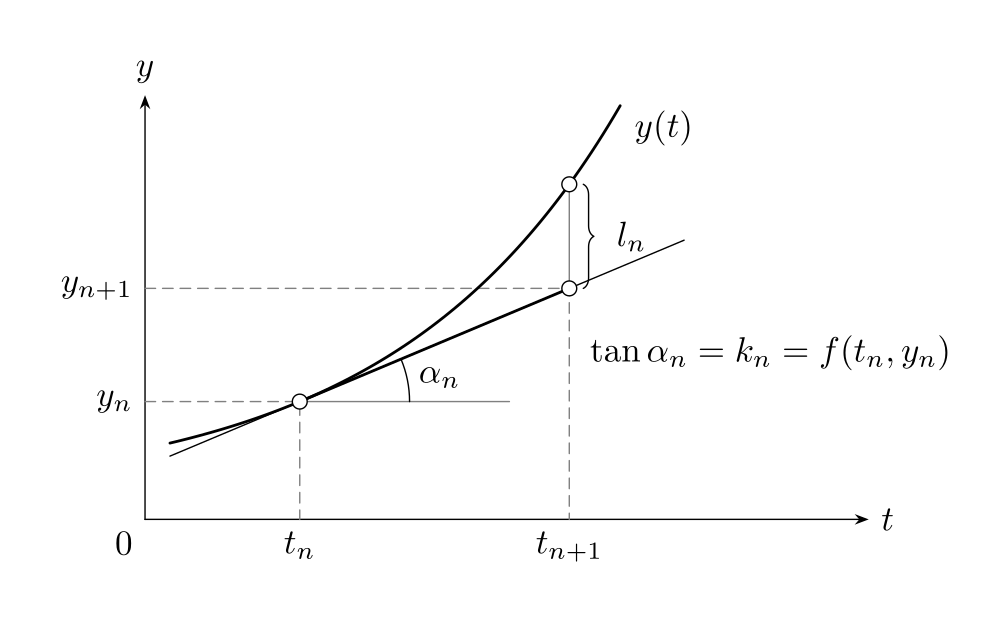

***Figure 1.*** *The Euler step and its local error*

Here $l_n$ is the difference at $t_{n+1}$ between the integral curve through $(t_n,y_n)$ and the Euler value $y_{n+1}$.

After $N$ steps, the integral curve is approximated by the Euler polyline, whose segment on $[t_n,t_{n+1}]$ has slope $f(t_n,y_n)$ (Figure 2).

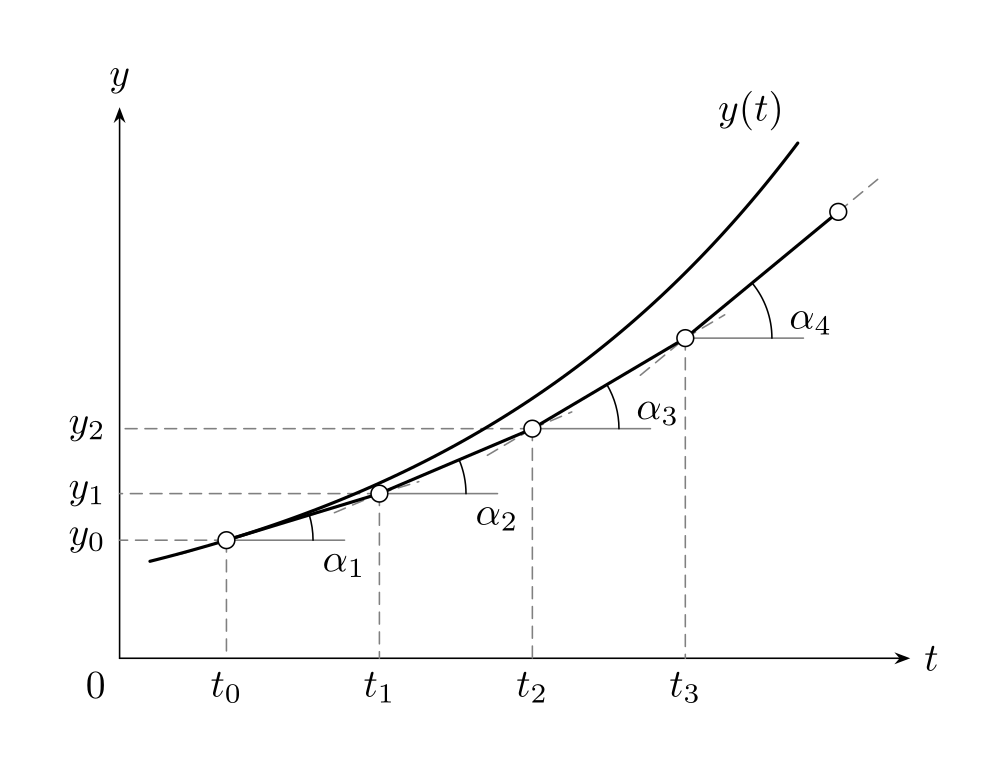

***Figure 2.*** *The Euler polyline and the exact solution through the initial point*

If the exact solution is twice continuously differentiable, Taylor's formula gives the approximation error (the residual divided by $h$):

$$
\psi_n=\frac{y(t_{n+1})-y(t_n)}{h}-f(t_n,y(t_n))=\frac h2 y''(\xi_n),\quad \xi_n\in(t_n,t_{n+1}). \tag{11}
$$

The local error of one step started from $y(t_n)$ is $h\psi_n$.

### 2.2. Stability

We first establish an auxiliary estimate.

**Lemma 1 (discrete growth estimate).** Let $z_n\geq 0$ and suppose that for $0\leq n<N$,

$$
z_{n+1}\leq (1+\alpha)z_n+\beta_n,\quad \alpha\geq 0,\quad \beta_n\geq 0. \tag{12}
$$

Then for $0\leq n\leq N$,

$$
z_n\leq e^{n\alpha}\left(z_0+\sum_{j=0}^{n-1}\beta_j\right). \tag{13}
$$

**Proof.** For $n=0$ the sum is empty and the bound is an equality. Assume that (13) holds at $n=m$. Using $1+\alpha\leq e^\alpha$ and $1\leq e^{(m+1)\alpha}$ gives

$$
\begin{aligned}
z_{m+1}&\leq (1+\alpha)z_m+\beta_m\leq e^\alpha z_m+e^{(m+1)\alpha}\beta_m\\
&\leq e^{(m+1)\alpha}\left(z_0+\sum_{j=0}^{m}\beta_j\right).
\end{aligned} \tag{14}
$$

This is (13) at $n=m+1$. $\square$

Let $y_n^*$ be the solution of the discrete problem with perturbed initial data and right-hand side:

$$
y_{n+1}^*=y_n^*+h\bigl(f(t_n,y_n^*)+\psi_n\bigr),\quad n=0,\ldots,N-1, \tag{15}
$$



$$
y^*(t_0)=y_0^*. \tag{16}
$$

**Theorem 1 (finite-interval stability of Euler's method).** Suppose $f$ is differentiable in $y$ on $[t_0,T]\times\mathbb R$ and $|f_y|\leq L$ there. Then the solutions of (10) and (15)–(16) satisfy

$$
\max_{0\leq n\leq N}|y_n^*-y_n|\leq e^{L(T-t_0)}\left(|y_0^*-y_0|+h\sum_{j=0}^{N-1}|\psi_j|\right). \tag{17}
$$

**Proof.** Subtract (10) from (15) and apply the mean value theorem to $f(t_n,\cdot)$ at an intermediate value $\widetilde y_n$ between $y_n$ and $y_n^*$:

$$
f(t_n,y_n^*)-f(t_n,y_n)=f_y(t_n,\widetilde y_n)(y_n^*-y_n). \tag{18}
$$

It follows that

$$
y_{n+1}^*-y_{n+1}=\bigl(1+h f_y(t_n,\widetilde y_n)\bigr)(y_n^*-y_n)+h\psi_n, \tag{19}
$$



$$
|y_{n+1}^*-y_{n+1}|\leq (1+hL)|y_n^*-y_n|+h|\psi_n|. \tag{20}
$$

With $z_n=|y_n^*-y_n|$, $\alpha=hL$, and $\beta_n=h|\psi_n|$, this is the recurrence from Lemma 1:

$$
z_{n+1}\leq (1+\alpha)z_n+\beta_n. \tag{21}
$$

The lemma gives

$$
|y_n^*-y_n|\leq e^{nhL}\left(|y_0^*-y_0|+h\sum_{j=0}^{n-1}|\psi_j|\right). \tag{22}
$$

Since $nh\leq Nh=T-t_0$, this implies (17). $\square$

**Remark 1 (Lipschitz condition).** Inequality (20) also follows directly if $f$ is uniformly Lipschitz in $y$ with constant $L$. Differentiability in $y$ is only needed for the mean-value argument above.

### 2.3. Error Estimate

By stability and first-order approximation, the Euler method converges with first-order accuracy. We can obtain a concrete bound directly.

**Theorem 2 (global error of Euler's method).** Suppose $f$ is uniformly Lipschitz in $y$ with constant $L$ on $[t_0,T]\times\mathbb R$, and the exact solution of (1) belongs to $C^2([t_0,T])$. If the starting value is exact, then

$$
\max_{0\leq n\leq N}|y(t_n)-y_n|\leq C(T)h, \tag{23}
$$

where

$$
C(T)=\frac12 e^{L(T-t_0)}(T-t_0)M_2,\quad M_2=\max_{t\in[t_0,T]}|y''(t)|. \tag{24}
$$

**Proof.** The definition of the approximation error (11) gives

$$
y(t_{n+1})=y(t_n)+h\bigl(f(t_n,y(t_n))+\psi_n\bigr). \tag{25}
$$

The exact grid values thus solve (15)–(16) with $y_0^*=y_0$. Theorem 1 and Remark 1 give

$$
\max_{0\leq n\leq N}|y(t_n)-y_n|\leq e^{L(T-t_0)} h\sum_{n=0}^{N-1}|\psi_n|. \tag{26}
$$

Finally,

$$
h\sum_{n=0}^{N-1}|\psi_n|\leq (T-t_0)\max_{0\leq n<N}|\psi_n|\leq (T-t_0)\frac h2 M_2. \tag{27}
$$

Substitution gives (23). $\square$

## 3. Runge–Kutta Methods

Euler, Euler–Cauchy, and improved Euler are simple examples of the widely used Runge–Kutta family of explicit one-step methods.

### 3.1. Derivation of Computational Formulas

Consider the exact solution on one step, with initial value $y(t_n)=y_n$ for this derivation. Integrating the differential equation gives

$$
y(t_{n+1})=y(t_n)+\int_{t_n}^{t_{n+1}} f(t,y(t))\,dt. \tag{28}
$$

The integral depends on the unknown solution. To approximate it by a quadrature sum, introduce $m$ auxiliary nodes:

$$
t_n^{(i)}=t_n+\alpha_i h,\quad i=1,\ldots,m,\quad \alpha_1=0,\quad 0\leq\alpha_i\leq 1. \tag{29}
$$

The first node is $t_n$. The last node is $t_{n+1}$ if $\alpha_m=1$; nodes can repeat, and the stages are evaluated in their specified order. The quadrature approximation is

$$
y(t_{n+1})\approx y(t_n)+h\sum_{i=1}^m c_i f(t_n^{(i)},y(t_n^{(i)})). \tag{30}
$$

The values $y(t_n^{(i)})$ for $i\geq 2$ are unknown. For each of them there is an identity analogous to (28):

$$
y(t_n^{(i)})=y(t_n)+\int_{t_n}^{t_n^{(i)}} f(t,y(t))\,dt,\quad i=2,\ldots,m. \tag{31}
$$

To obtain an explicit method, use only previously evaluated stages in the quadrature for each of these integrals:

$$
y(t_n^{(2)})\approx y(t_n)+h\beta_{21}f(t_n^{(1)},y(t_n^{(1)})), \tag{32}
$$



$$
y(t_n^{(3)})\approx y(t_n)+h\bigl(\beta_{31}f(t_n^{(1)},y(t_n^{(1)}))+\beta_{32}f(t_n^{(2)},y(t_n^{(2)}))\bigr), \tag{33}
$$



$$
y(t_n^{(i)})\approx y(t_n)+h\sum_{j=1}^{i-1}\beta_{ij}f(t_n^{(j)},y(t_n^{(j)})),\quad i=2,\ldots,m, \tag{34}
$$



$$
y(t_n^{(m)})\approx y(t_n)+h\sum_{j=1}^{m-1}\beta_{mj}f(t_n^{(j)},y(t_n^{(j)})). \tag{35}
$$

The quadrature on each stage interval integrates constants exactly if $\sum_{j<i}\beta_{ij}=\alpha_i$. For the full-step quadrature the corresponding condition is $\sum_i c_i=1$.

**Definition 3 (explicit $m$-stage Runge–Kutta method).** Denote the stage approximations by $y_n^{(i)}$ and the corresponding slopes by $k_n^{(i)}=f(t_n^{(i)},y_n^{(i)})$. The method uses the weighted slope

$$
y_{n+1}=y_n+h k_n,\quad k_n=\sum_{i=1}^m c_i k_n^{(i)}, \tag{36}
$$

with the stages evaluated in succession:

$$
y_n^{(1)}=y_n,\quad k_n^{(1)}=f(t_n^{(1)},y_n^{(1)}), \tag{37}
$$



$$
y_n^{(2)}=y_n+h\beta_{21}k_n^{(1)},\quad k_n^{(2)}=f(t_n^{(2)},y_n^{(2)}), \tag{38}
$$



$$
y_n^{(3)}=y_n+h(\beta_{31}k_n^{(1)}+\beta_{32}k_n^{(2)}),\quad k_n^{(3)}=f(t_n^{(3)},y_n^{(3)}), \tag{39}
$$



$$
y_n^{(i)}=y_n+h\sum_{j=1}^{i-1}\beta_{ij}k_n^{(j)},\quad k_n^{(i)}=f(t_n^{(i)},y_n^{(i)}),\quad i=2,\ldots,m. \tag{40}
$$

Eliminating the auxiliary stage values yields the familiar computational form:

$$
y_{n+1}=y_n+h\sum_{i=1}^m c_i k_n^{(i)}, \tag{41}
$$



$$
k_n^{(1)}=f(t_n,y_n), \tag{42}
$$



$$
k_n^{(2)}=f(t_n+\alpha_2 h,\,y_n+h\beta_{21}k_n^{(1)}), \tag{43}
$$



$$
k_n^{(3)}=f(t_n+\alpha_3 h,\,y_n+h(\beta_{31}k_n^{(1)}+\beta_{32}k_n^{(2)})), \tag{44}
$$



$$
k_n^{(i)}=f\!\left(t_n+\alpha_i h,\,y_n+h\sum_{j=1}^{i-1}\beta_{ij}k_n^{(j)}\right),\quad i=2,\ldots,m. \tag{45}
$$

In particular, this is a one-step method of the form

$$
y_{n+1}=y_n+h\Phi(t_n,y_n,h), \tag{46}
$$

where the increment function uses $m$ evaluations of the right-hand side:

$$
\Phi(t_n,y_n,h)=\sum_{i=1}^m c_i k_n^{(i)}. \tag{47}
$$

One of the main goals in choosing the coefficients is to obtain a high approximation order.

### 3.2. Stability and Convergence

**Theorem 3 (finite-interval stability of explicit Runge–Kutta methods).** Suppose $f$ is uniformly Lipschitz in $y$ on $[t_0,T]\times\mathbb R$ and the coefficients of (41)–(45) are fixed. Then the method is stable on the fixed interval.

**Proof.** For two inputs at the same node, let $d$ be the absolute difference of the inputs and $\Delta k^{(i)}$ the corresponding difference of stage slopes. Fix an upper bound $H$ for $h$ and let $L$ be the Lipschitz constant. Set $K_1=L$ and $K_i=L(1+H\sum_{j<i}|\beta_{ij}|K_j)$. The stage formulas give by induction

$$
|\Delta k^{(i)}|\leq L\left(d+h\sum_{j<i}|\beta_{ij}|\,|\Delta k^{(j)}|\right)\leq K_i d. \tag{48}
$$

Thus $\Phi$ has a Lipschitz constant $L_\Phi=\sum_i|c_i|K_i$ independent of $h$. For a perturbation $h\psi_n$ of the update, the difference satisfies the inequality of Lemma 1 with $\alpha=hL_\Phi$ and $\beta_n=h|\psi_n|$. This gives the finite-interval bound (17) with $L_\Phi$ in place of $L$. $\square$

**Corollary 1 (order of convergence).** Under the assumptions of Theorem 3, if the method has approximation order $p$ along the exact solution and the initial value is exact or accurate to $O(h^p)$, then it converges with order $p$. This follows from Theorem 4 of Lecture 06.1.

### 3.3. Family of Explicit Two-Stage Methods

We now derive a family of explicit two-stage methods of second-order accuracy. Start with

$$
y_{n+1}=y_n+h(c_1 k_n^{(1)}+c_2 k_n^{(2)}), \tag{49}
$$



$$
k_n^{(1)}=f(t_n,y_n),\quad k_n^{(2)}=f(t_n+\alpha h,\,y_n+h\beta k_n^{(1)}). \tag{50}
$$

Equivalently,

$$
\frac{y_{n+1}-y_n}{h}=c_1 f(t_n,y_n)+c_2 f(t_n+\alpha h,\,y_n+h\beta f(t_n,y_n)). \tag{51}
$$

Write $t=t_n$, $y=y(t_n)$, and $f=f(t,y)$. The approximation error is

$$
\psi_n=\frac{y(t+h)-y(t)}{h}-c_1 f-c_2 f(t+\alpha h,\,y+h\beta f). \tag{52}
$$

Assume $f$ is $C^2$ in a neighborhood of the exact solution, so the Taylor expansions below hold uniformly for small $h$. Expanding the solution gives

$$
y(t+h)=y(t)+y'(t)h+\frac{y''(t)}2h^2+O(h^3). \tag{53}
$$

Using (5) and (6) gives

$$
\frac{y(t+h)-y(t)}h=f+\frac12(f_t+f_yf)h+O(h^2). \tag{54}
$$

Taylor expansion of the second stage about $(t,y)$ gives

$$
f(t+\alpha h,\,y+h\beta f)=f+(\alpha f_t+\beta f_y f)h+O(h^2). \tag{55}
$$

Subtracting the stage terms, we find

$$
\psi_n=(1-c_1-c_2)f+h\left[\left(\frac12-c_2\alpha\right)f_t+\left(\frac12-c_2\beta\right)f_y f\right]+O(h^2). \tag{56}
$$

For the constant and linear terms to vanish for general $f$, require

$$
c_1+c_2=1,\quad c_2\alpha=\frac12,\quad c_2\beta=\frac12. \tag{57}
$$

Thus $\beta=\alpha$, $c_2=1/(2\alpha)$, and $c_1=1-1/(2\alpha)$. For any fixed $\alpha\in(0,1]$, the resulting scheme is

$$
\begin{aligned}
y_{n+1}=y_n+h\biggl[&\left(1-\frac{1}{2\alpha}\right)f(t_n,y_n)\\
&+\frac{1}{2\alpha} f(t_n+\alpha h,\,y_n+\alpha h f(t_n,y_n))\biggr].
\end{aligned} \tag{58}
$$

Its approximation error is $O(h^2)$, so Corollary 1 gives second-order convergence under the stability assumptions of Theorem 3. For $\alpha=1$ we obtain the Euler–Cauchy method (explicit trapezoidal rule); for $\alpha=1/2$ we obtain the improved Euler method (explicit midpoint rule).

### 3.4. Runge–Kutta Method of Fourth-Order Accuracy

**Definition 4 (classical fourth-order Runge–Kutta method).** This four-stage method uses the formulas

$$
\begin{aligned}
y_{n+1}&=y_n+h k_n,\quad k_n=\tfrac16(k_n^{(1)}+2k_n^{(2)}+2k_n^{(3)}+k_n^{(4)}),\\
k_n^{(1)}&=f(t_n,y_n),\\
k_n^{(2)}&=f\!\left(t_n+\tfrac h2,\,y_n+\tfrac h2 k_n^{(1)}\right),\\
k_n^{(3)}&=f\!\left(t_n+\tfrac h2,\,y_n+\tfrac h2 k_n^{(2)}\right),\\
k_n^{(4)}&=f(t_n+h,\,y_n+h k_n^{(3)}).
\end{aligned} \tag{59}
$$

For $f\in C^4$ near the exact solution, the stages match the Taylor expansion of the exact one-step increment through degree four in $h$ (see [1]). The local error is $O(h^5)$, and Corollary 1 gives global error $O(h^4)$ under the stability assumptions above. The method is simple and effective for many nonstiff problems.

**Remark 2 (connection with Simpson's rule).** In the quadrature problem $y'=f(t)$ discussed in Lecture 06.1, the two midpoint stages coincide. Thus (59) reduces to Simpson's rule on one step:

$$
y_{n+1}=y_n+\frac h6\left[f(t_n)+4f\!\left(t_n+\frac h2\right)+f(t_{n+1})\right]. \tag{60}
$$

**Example 1 (checking the orders on the model equation).** For $y'=\lambda y$ and $z=h\lambda$, one step has the form $y_{n+1}=R(z)y_n$. Substituting into (10), (58), and (59) gives

$$
R_1(z)=1+z,\quad R_2(z)=1+z+\tfrac{z^2}{2},\quad R_4(z)=1+z+\tfrac{z^2}{2}+\tfrac{z^3}{6}+\tfrac{z^4}{24}. \tag{61}
$$

Each polynomial matches the expansion of $e^z$ through its indicated degree. For repeated steps on the model equation the amplification is $R(z)^n$. Decay therefore requires $|R(z)|<1$; finite-interval stability as $h\to0$ does not guarantee decay at an arbitrary fixed step.

## 4. Linear Multistep Methods. Adams Methods

### 4.1. Construction of Adams Methods

In a one-step method, once $y_n$ is found, $y_{n-1}$ is no longer needed. A multistep method can also use information retained at the earlier nodes $t_{n-k+1},\ldots,t_{n-1}$.

**Definition 5 ($k$-step Adams method).** With $f_j=f(t_j,y_j)$ and fixed coefficients $\beta_0,\ldots,\beta_k$, an Adams method has the form

$$
\frac{y_{n+1}-y_n}{h}=\sum_{j=0}^k\beta_j f_{n+1-j},\quad n=k-1,\ldots,N-1. \tag{62}
$$

The method uses $k$ known values $y_n,\ldots,y_{n-k+1}$ and starts from $y_0,\ldots,y_{k-1}$. The additional starting values can be computed by a one-step method of sufficient order.

When $\beta_0=0$, the method is explicit:

$$
y_{n+1}=y_n+h\sum_{j=1}^k\beta_j f_{n+1-j}. \tag{63}
$$

When $\beta_0\ne 0$, the method is implicit and the new value must be found from the equation

$$
y_{n+1}=g_n+h\beta_0 f(t_{n+1},y_{n+1}), \tag{64}
$$

where the known part is

$$
g_n=y_n+h\sum_{j=1}^k\beta_j f_{n+1-j}. \tag{65}
$$

As in the derivation of the Runge–Kutta formulas, we start from the exact identity

$$
y(t_{n+1})=y(t_n)+\int_{t_n}^{t_{n+1}}F(t)\,dt,\quad F(t)=f(t,y(t)). \tag{66}
$$

Interpolate $F$ by a polynomial $P_{k-1}$ of degree at most $k-1$ at the $k$ known nodes $t_{n+1-k},\ldots,t_n$. Integrating its Lagrange form gives the quadrature approximation

$$
\int_{t_n}^{t_{n+1}}F(t)\,dt\approx\int_{t_n}^{t_{n+1}}P_{k-1}(t)\,dt=h\sum_{j=1}^k\beta_j F(t_{n+1-j}). \tag{67}
$$

Replacing $F(t_j)$ by $f_j$ in the quadrature gives (63), the explicit $k$-step **Adams–Bashforth method**.

**Remark 3 (extrapolation).** Except for $t_n$, the integration interval lies outside the interval spanned by the known nodes. This is why (67) is called an extrapolation formula.

If we include $t_{n+1}$ along with $t_{n+1-k},\ldots,t_n$, the interpolation polynomial $Q_k$ has degree at most $k$. Integrating it in (66) and using the grid values gives

$$
y_{n+1}=y_n+h\sum_{j=0}^k\beta_j f_{n+1-j}. \tag{68}
$$

This gives the implicit $k$-step **Adams–Moulton method**. The weights come from the new interpolation stencil and differ from the Adams–Bashforth weights.

**Remark 4 (interpolation).** The Adams–Moulton method is called the interpolation Adams method because the integration interval lies between its interpolation nodes.

**Example 2 (two-step Adams–Bashforth and one-step Adams–Moulton).** The linear interpolation polynomials are

$$
P_1(t)=f_n+\frac{t-t_n}{h}(f_n-f_{n-1}), \tag{69}
$$



$$
Q_1(t)=f_n\frac{t_{n+1}-t}{h}+f_{n+1}\frac{t-t_n}{h}. \tag{70}
$$

Integrating over one step gives

$$
\int_{t_n}^{t_{n+1}}P_1(t)\,dt=h\left(\frac32 f_n-\frac12 f_{n-1}\right), \tag{71}
$$



$$
\int_{t_n}^{t_{n+1}}Q_1(t)\,dt=h\left(\frac12 f_n+\frac12 f_{n+1}\right). \tag{72}
$$

Thus the two-step Adams–Bashforth formula is

$$
y_{n+1}=y_n+\frac h2(3f_n-f_{n-1}), \tag{73}
$$

and the one-step Adams–Moulton formula is the implicit trapezoidal rule:

$$
y_{n+1}=y_n+\frac h2(f_n+f_{n+1}). \tag{74}
$$

### 4.2. Approximation, Stability, and Convergence

**Proposition 1 (order of Adams methods).** Let $k\geq 2$ and $y\in C^{k+1}([t_0,T])$. Then the $k$-step Adams–Bashforth method and the $(k-1)$-step Adams–Moulton method have approximation order $k$.

**Proof.** In both cases the quadrature uses $k$ nodes $s_1,\ldots,s_k$ and integrates polynomials of degree at most $k-1$ exactly. The interpolation remainder for $F=y'$ on the integration interval is

$$
F(t)-P(t)=\frac{F^{(k)}(\xi_t)}{k!}\prod_{i=1}^k(t-s_i), \tag{75}
$$

Here $P$ is the interpolating polynomial and $\xi_t$ lies in the interval containing the nodes and $t$. Each factor is $O(h)$ for fixed $k$. Integrating over one step and dividing by $h$ yields $O(h^k)$ uniformly in $n$. For $F(t)=t^k$, the product has a fixed nonzero sign in the interior of the integration interval for either stencil, so the residual has a nonzero term of order $h^k$. $\square$

**Theorem 4 (finite-interval stability of Adams methods).** Suppose $f$ is uniformly Lipschitz in $y$ with constant $L$ on $[t_0,T]\times\mathbb R$. Explicit Adams methods with fixed coefficients are stable on the fixed interval. The implicit methods are uniquely solvable at each step and stable on the fixed interval under the sufficient condition

$$
h|\beta_0|L\leq \frac12. \tag{76}
$$

**Proof.** The right-hand side of (64), viewed as a map of $y_{n+1}$, is a contraction under (76). Let $d_j=|y_j^*-y_j|$, $E_n=\max_{0\leq j\leq n}d_j$, and let $h\psi_n$ be the additive perturbation of the update. Subtracting the two updates and applying the Lipschitz bound gives

$$
(1-h|\beta_0|L)d_{n+1}\leq \left(1+hL\sum_{j=1}^k|\beta_j|\right)E_n+h|\psi_n|. \tag{77}
$$

The factor on the left is at least $1/2$ (it equals $1$ when $\beta_0=0$). Set $B=L\sum_{j=0}^k|\beta_j|$. Then $E_{n+1}\leq (1+2hB)E_n+2h|\psi_n|$. Lemma 1, applied starting at $n=k-1$, gives the desired bound independent of $h$. $\square$

**Remark 5 (monotone right-hand side).** If $f_y\leq 0$ everywhere and $\beta_0>0$, the scalar map $u\mapsto u-h\beta_0 f(t_{n+1},u)$ is onto and its inverse is $1$-Lipschitz for every $h>0$: its increments have the same sign as those of $u$ and absolute value at least as large. Under the Lipschitz hypothesis of Theorem 4, we can then use a factor of $1$ on the left of (77), with no step restriction in that finite-interval estimate. Absolute stability still requires a separate check. For instance, the order-three Adams–Moulton method applied to $y'=\lambda y$ with $h\lambda=-12$ has characteristic polynomial $6r^2+7r-1$, with a root of modulus greater than $1$.

**Corollary 2 (order of convergence).** Under the stability assumptions of Theorem 4, a $k$-step Adams method of approximation order $p$ converges with order $p$ if all starting errors are $O(h^p)$. This follows from Theorem 4 of Lecture 06.1.

### 4.3. Adams–Bashforth Formulas

For $p=2$ the formula is (73). For $p=3$ and $p=4$, integration of the interpolation polynomials gives, respectively,

$$
y_{n+1}=y_n+\frac h{12}(23f_n-16f_{n-1}+5f_{n-2}), \tag{78}
$$



$$
y_{n+1}=y_n+\frac h{24}(55f_n-59f_{n-1}+37f_{n-2}-9f_{n-3}). \tag{79}
$$

### 4.4. Adams–Moulton Formulas

For $p=2$ the formula is (74). For $p=3$ and $p=4$ the formulas are, respectively,

$$
y_{n+1}=y_n+\frac h{12}(5f_{n+1}+8f_n-f_{n-1}), \tag{80}
$$



$$
y_{n+1}=y_n+\frac h{24}(9f_{n+1}+19f_n-5f_{n-1}+f_{n-2}). \tag{81}
$$

**Example 3 (checking the Adams weights).** In the scaled coordinate $s=(t-t_n)/h$, exactness for $1,s,\ldots,s^{p-1}$ requires

$$
\sum_i w_i s_i^q=\int_0^1 s^q\,ds=\frac1{q+1},\quad q=0,\ldots,p-1. \tag{82}
$$

For (78), the nodes $0,-1,-2$ with weights $(23,-16,5)/12$ give the moments $1,1/2,1/3$. For (80), the nodes $1,0,-1$ with weights $(5,8,-1)/12$ give the same three moments.

## References

1. **E. Hairer, S. P. Nørsett, G. Wanner.** *Solving Ordinary Differential Equations I: Nonstiff Problems.* 2nd revised edition. Springer, 1993. Taylor, Runge–Kutta, and Adams methods for nonstiff problems.
2. **J. C. Butcher.** *Numerical Methods for Ordinary Differential Equations.* 3rd edition. Wiley, 2016. One-step and multistep methods.
3. **A. Iserles.** *A First Course in the Numerical Analysis of Differential Equations.* 2nd edition. Cambridge University Press, 2009. Discretization, error propagation, and stability.